In [21]:
import os
import glob
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")


IMAGES_DIR_G1020 = "/kaggle/input/datasets/arnavjain1/glaucoma-datasets/G1020/Images_Square"
MASKS_DIR_G1020 = "/kaggle/input/datasets/arnavjain1/glaucoma-datasets/G1020/Masks_Square"

IMAGES_DIR_ORIGA = "/kaggle/input/datasets/arnavjain1/glaucoma-datasets/ORIGA/Images_Square"
MASKS_DIR_ORIGA = "/kaggle/input/datasets/arnavjain1/glaucoma-datasets/ORIGA/Masks_Square"

IMAGES_DIR_REFUGE = "/kaggle/input/datasets/arnavjain1/glaucoma-datasets/REFUGE/Images_Square"
MASKS_DIR_REFUGE = "/kaggle/input/datasets/arnavjain1/glaucoma-datasets/REFUGE/Masks_Square"

N_TEST = 200   # number of REFUGE images kept for the test set


image_paths = []
mask_paths = []

image_paths.extend(sorted(glob.glob(os.path.join(IMAGES_DIR_G1020, "*.*"))))
mask_paths.extend(sorted(glob.glob(os.path.join(MASKS_DIR_G1020, "*.*"))))

image_paths.extend(sorted(glob.glob(os.path.join(IMAGES_DIR_ORIGA, "*.*"))))
mask_paths.extend(sorted(glob.glob(os.path.join(MASKS_DIR_ORIGA, "*.*"))))


# ---------- REFUGE: 200 random images -> Test, the rest -> Train/Val ----------
refuge_imgs = sorted(glob.glob(os.path.join(IMAGES_DIR_REFUGE, "*.*")))
refuge_masks = sorted(glob.glob(os.path.join(MASKS_DIR_REFUGE, "*.*")))

refuge_trainval_imgs, test_imgs, refuge_trainval_masks, test_masks = train_test_split(
    refuge_imgs, refuge_masks, test_size=N_TEST, random_state=42
)

image_paths.extend(refuge_trainval_imgs)
mask_paths.extend(refuge_trainval_masks)

print(f"REFUGE total: {len(refuge_imgs)}  ->  Test: {len(test_imgs)} | to Train/Val: {len(refuge_trainval_imgs)}")
print(f"Total Images for Train+Val: {len(image_paths)}")
print(f"Total Masks for Train+Val:  {len(mask_paths)}")


train_imgs, val_imgs, train_masks, val_masks = train_test_split(
    image_paths, mask_paths, test_size=0.2, random_state=42
)

print(f"Training Samples: {len(train_imgs)}")
print(f"Validation Samples: {len(val_imgs)}")
print(f"Test Samples: {len(test_imgs)}")

REFUGE total: 1200  ->  Test: 200 | to Train/Val: 1000
Total Images for Train+Val: 2670
Total Masks for Train+Val:  2670
Training Samples: 2136
Validation Samples: 534
Test Samples: 200


In [22]:
import cv2
img=cv2.imread(train_masks[50])
img.max()

np.uint8(1)

In [23]:
!pip install -q albumentations

In [24]:
import cv2
import numpy as np
import tensorflow as tf
import albumentations as A

IMG_HEIGHT = 256
IMG_WIDTH = 256
NUM_CLASSES = 3


# =====================================================================
# Augmentation (Albumentations): the SAME random geometric transform is
# applied to the image and its mask. Colour / blur / contrast transforms
# only touch the image, and the mask is always resized/warped with
# nearest-neighbour so its labels stay exactly {0, 1, 2}.
# =====================================================================
train_transform = A.Compose([
    # geometric  -> applied to image + mask together
    A.HorizontalFlip(p=0.1),
    A.VerticalFlip(p=0.1),
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-25, 25), p=0.7),

    # pixel-level -> applied to image only
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.RandomGamma(gamma_limit=(80, 120), p=0.3),
    A.CLAHE(clip_limit=2.0, p=0.3),
    A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=15, val_shift_limit=10, p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
])


def _load_resize(image_path, mask_path):
    """Read + resize with OpenCV (image: bilinear, mask: nearest). Returns uint8 arrays."""
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_NEAREST)
    return img, mask


def _augment_py(image_path, mask_path):
    image_path = image_path.decode("utf-8")
    mask_path = mask_path.decode("utf-8")

    img, mask = _load_resize(image_path, mask_path)
    out = train_transform(image=img, mask=mask)

    image = out["image"].astype(np.float32) / 255.0
    mask = out["mask"].astype(np.int32)
    return image, mask


def augment_image_and_mask(image_path, mask_path):
    image, mask = tf.numpy_function(
        _augment_py, [image_path, mask_path], [tf.float32, tf.int32]
    )
    image.set_shape([IMG_HEIGHT, IMG_WIDTH, 3])
    mask.set_shape([IMG_HEIGHT, IMG_WIDTH])
    mask = tf.one_hot(mask, depth=NUM_CLASSES)
    return image, mask


# ---------- no augmentation (used for Val and Test) -- unchanged ----------
def load_image_and_mask(image_path, mask_path):

    image_file = tf.io.read_file(image_path)
    image = tf.image.decode_image(image_file, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_HEIGHT, IMG_WIDTH])
    image = tf.cast(image, tf.float32) / 255.0

    mask_file = tf.io.read_file(mask_path)
    mask = tf.image.decode_image(mask_file, channels=1, expand_animations=False)
    mask = tf.image.resize(mask, [IMG_HEIGHT, IMG_WIDTH], method='nearest')

    mask = tf.cast(tf.round(mask), tf.int32)
    mask = tf.squeeze(mask, axis=-1)  

    mask = tf.one_hot(mask, depth=3) 
    
    return image, mask


def create_dataset(image_paths, mask_paths, batch_size=8, is_train=False, augment=False):
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))

    # augmentation only on the training set
    map_fn = augment_image_and_mask if (is_train and augment) else load_image_and_mask
    dataset = dataset.map(map_fn, num_parallel_calls=tf.data.AUTOTUNE)
    
    if is_train:
        dataset = dataset.shuffle(buffer_size=100)
        
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
    return dataset


BATCH_SIZE = 16
train_dataset = create_dataset(train_imgs, train_masks, batch_size=BATCH_SIZE, is_train=True, augment=True)
val_dataset = create_dataset(val_imgs, val_masks, batch_size=BATCH_SIZE, is_train=False)
test_dataset = create_dataset(test_imgs, test_masks, batch_size=BATCH_SIZE, is_train=False)   # REFUGE (test only)
print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))
for images, masks in train_dataset.take(1):
    print("Image shape:", images.shape)
    print("Mask shape (One-Hot):", masks.shape) 
    print("Min mask value:", tf.reduce_min(masks).numpy())
    print("Max mask value:", tf.reduce_max(masks).numpy())
    break

134
34
13
Image shape: (16, 256, 256, 3)
Mask shape (One-Hot): (16, 256, 256, 3)
Min mask value: 0.0
Max mask value: 1.0


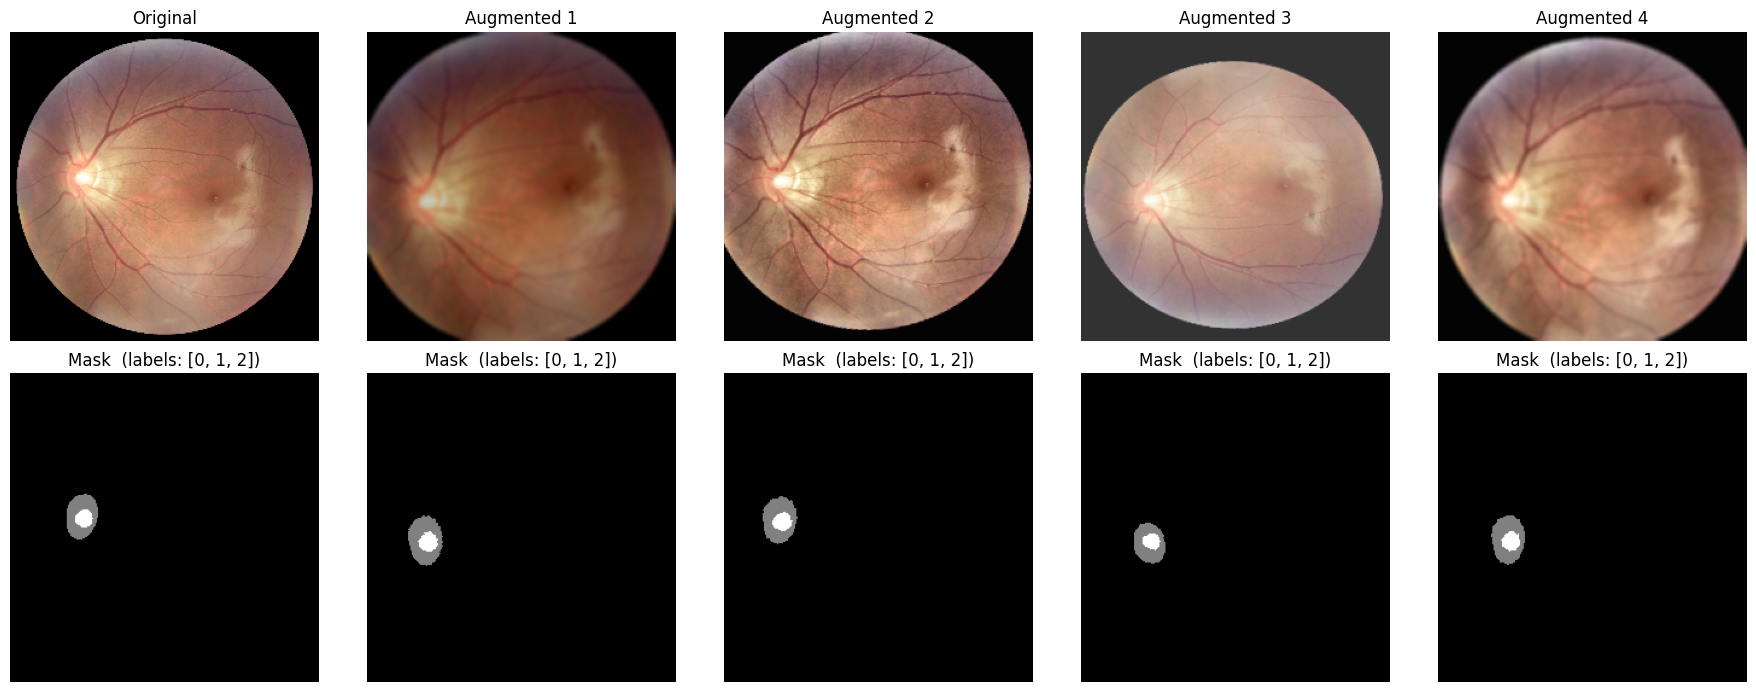

In [25]:
# Sanity check: same image augmented several times -> mask must follow the image
import matplotlib.pyplot as plt

idx = 0
img0, mask0 = _load_resize(train_imgs[idx], train_masks[idx])

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for j in range(5):
    if j == 0:
        img, msk, title = img0, mask0, "Original"
    else:
        out = train_transform(image=img0, mask=mask0)
        img, msk, title = out["image"], out["mask"], f"Augmented {j}"

    axes[0, j].imshow(img)
    axes[0, j].set_title(title)
    axes[0, j].axis("off")

    axes[1, j].imshow(msk, cmap="gray", vmin=0, vmax=2)
    axes[1, j].set_title(f"Mask  (labels: {np.unique(msk).tolist()})")
    axes[1, j].axis("off")

plt.tight_layout()
plt.show()

In [26]:
import tensorflow as tf
from tensorflow.keras import backend as K

def dice_loss(y_true, y_pred, smooth=1e-6):
    
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    
    intersection = K.sum(y_true_f * y_pred_f)
    dice = (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)
    
    return 1. - dice

def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

In [27]:
!pip install -q segmentation-models

In [28]:
import os
os.environ["SM_FRAMEWORK"] = "tf.keras"

import segmentation_models as sm
from segmentation_models import Unet
from segmentation_models.losses import bce_jaccard_loss
from segmentation_models.metrics import iou_score

BACKBONE = 'resnet34'
LR = 0.0001

model = Unet(
    backbone_name=BACKBONE, 
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    classes=3, 
    activation='softmax',
    encoder_weights='imagenet'
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss= dice_loss,
    metrics=[iou_score, dice_coef]
)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ data (InputLayer)   │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_data             │ (None, 256, 256,  │          9 │ data[0][0]        │
│ (BatchNormalizatio… │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_34   │ (None, 262, 262,  │          0 │ bn_data[0][0]     │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv0 (Conv2D)      │ (None, 128, 128,  │      9,408 │ zero_padding2d_3… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn0                 │ (None, 128, 128,  │        256 │ conv0[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu0 (Activation)  │ (None, 128, 128,  │          0 │ bn0[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_35   │ (None, 130, 130,  │          0 │ relu0[0][0]       │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pooling0            │ (None, 64, 64,    │          0 │ zero_padding2d_3… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_bn1    │ (None, 64, 64,    │        256 │ pooling0[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_relu1  │ (None, 64, 64,    │          0 │ stage1_unit1_bn1… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_36   │ (None, 66, 66,    │          0 │ stage1_unit1_rel… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_conv1  │ (None, 64, 64,    │     36,864 │ zero_padding2d_3… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_bn2    │ (None, 64, 64,    │        256 │ stage1_unit1_con… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_relu2  │ (None, 64, 64,    │          0 │ stage1_unit1_bn2… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_37   │ (None, 66, 66,    │          0 │ stage1_unit1_rel… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_conv2  │ (None, 64, 64,    │     36,864 │ zero_padding2d_3… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_sc     │ (None, 64, 64,    │      4,096 │ stage1_unit1_rel

 Total params: 24,456,444 (93.29 MB)

 Trainable params: 24,439,094 (93.23 MB)

 Non-trainable params: 17,350 (67.77 KB)

In [29]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_glaucoma_model_ResNet34.keras",
        monitor="val_iou_score",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_iou_score",
        patience=6,
        restore_best_weights=True,
        verbose=1,
        mode='max'
    )
]

EPOCHS = 100

history_1 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/100
133/134 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step - dice_coef: 0.5615 - iou_score: 0.1992 - loss: 0.4385

2026-10-28 15:38:25.956749: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 15:38:26.263367: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 15:38:26.458973: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng4{k11=1} for conv (f32[8,32,128,128]{3,2,1,0}, u8[0]{0}) custom-call(f32[8,32,128,128]{3,2,1,0}, f32[32,32,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBackwardInput", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"

134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - dice_coef: 0.5625 - iou_score: 0.1995 - loss: 0.4375
Epoch 1: val_iou_score improved from None to 0.26776, saving model to best_glaucoma_model_ResNet34.keras

Epoch 1: finished saving model to best_glaucoma_model_ResNet34.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 123s 659ms/step - dice_coef: 0.6846 - iou_score: 0.2469 - loss: 0.3160 - val_dice_coef: 0.7883 - val_iou_score: 0.2678 - val_loss: 0.2117 - learning_rate: 1.0000e-04
Epoch 2/100
134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step - dice_coef: 0.8832 - iou_score: 0.3349 - loss: 0.1168
Epoch 2: val_iou_score improved from 0.26776 to 0.30636, saving model to best_glaucoma_model_ResNet34.keras

Epoch 2: finished saving model to best_glaucoma_model_ResNet34.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 46s 335ms/step - dice_coef: 0.9064 - iou_score: 0.3513 - loss: 0.0938 - val_dice_coef: 0.9064 - val_iou_score: 0.3064 - val_loss: 0.0936 - learning_rate: 1.0000e-04
Epoch 3/100
134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/

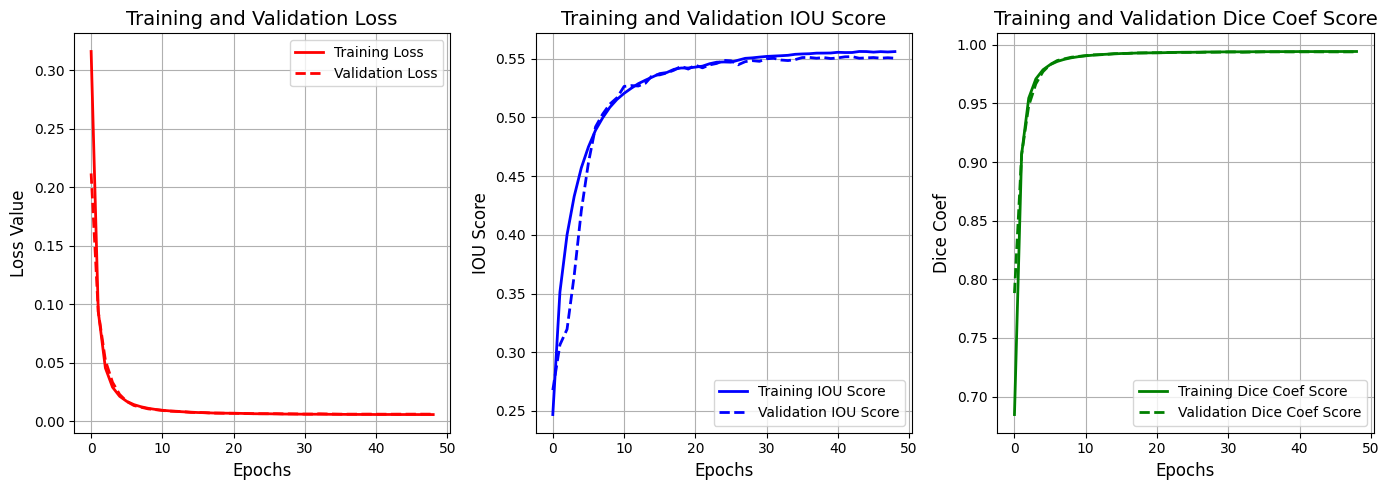

In [30]:
import matplotlib.pyplot as plt

loss = history_1.history['loss']
val_loss = history_1.history['val_loss']

iou = history_1.history['iou_score']
val_iou = history_1.history['val_iou_score']

dice_hist = history_1.history['dice_coef']
val_dice_hist = history_1.history['val_dice_coef']


epochs_range = range(len(loss))


plt.figure(figsize=(14, 5))


plt.subplot(1, 3, 1)
plt.plot(epochs_range, loss, label='Training Loss', color='red', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='red', linewidth=2, linestyle='--')
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss Value', fontsize=12)
plt.legend()
plt.grid(True)


plt.subplot(1, 3, 2)
plt.plot(epochs_range, iou, label='Training IOU Score', color='blue', linewidth=2)
plt.plot(epochs_range, val_iou, label='Validation IOU Score', color='blue', linewidth=2, linestyle='--')
plt.title('Training and Validation IOU Score', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('IOU Score', fontsize=12)
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(epochs_range, dice_hist, label='Training Dice Coef Score', color='green', linewidth=2)
plt.plot(epochs_range, val_dice_hist, label='Validation Dice Coef Score', color='green', linewidth=2, linestyle='--')
plt.title('Training and Validation Dice Coef Score', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Dice Coef', fontsize=12)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


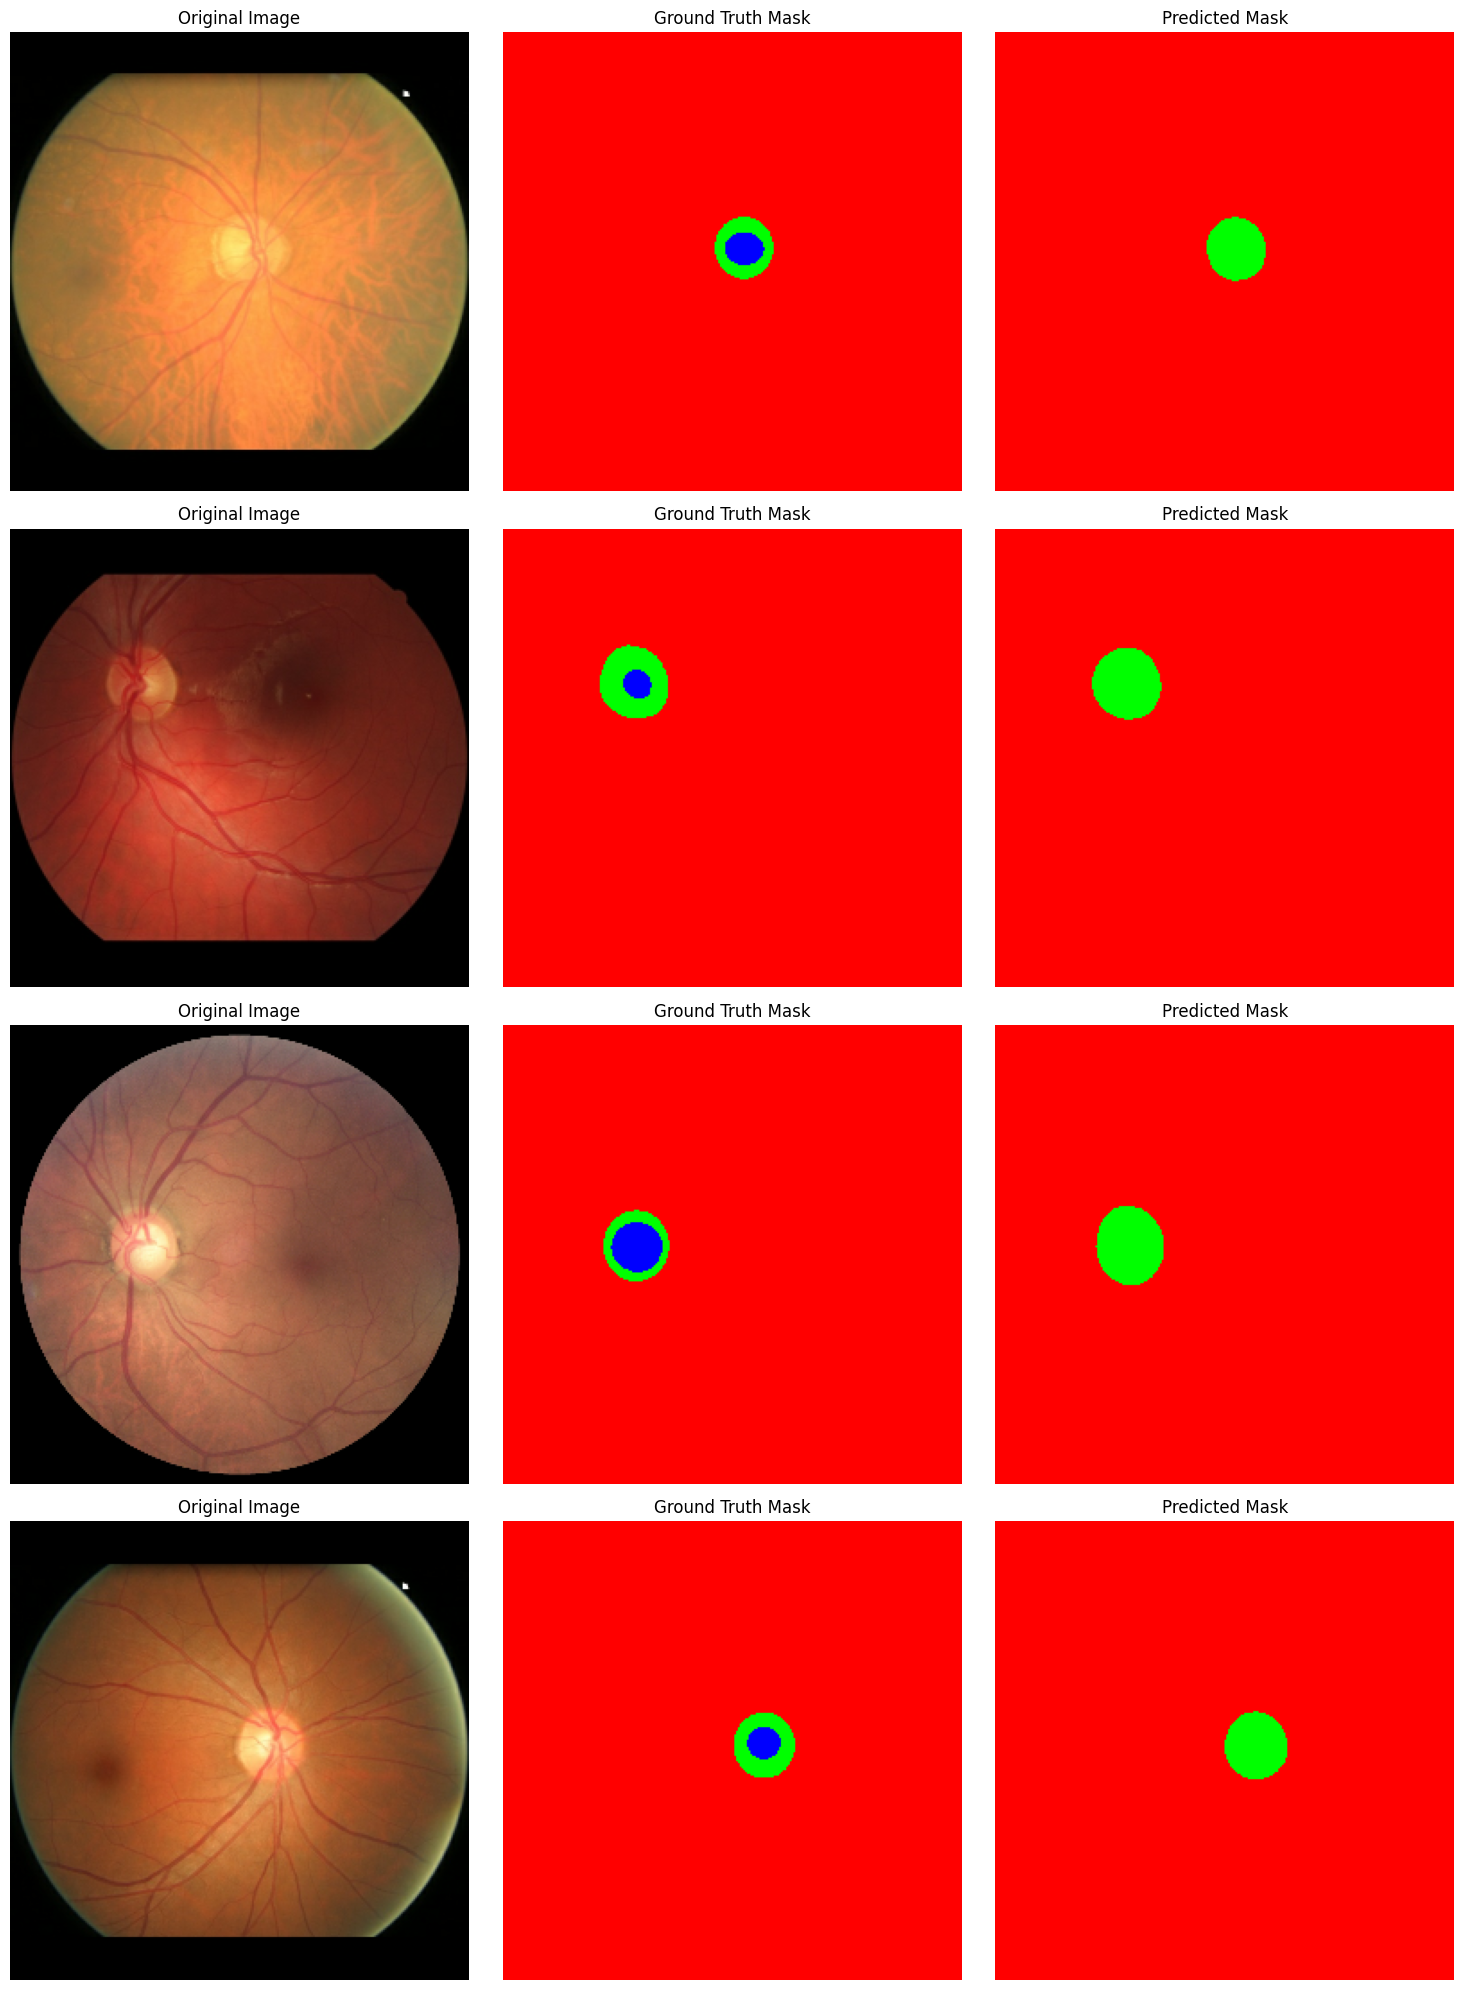

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf


best_model = tf.keras.models.load_model(
    "/kaggle/working/best_glaucoma_model_ResNet34.keras", 
    compile=False
)


def visualize_predictions(dataset, model, num_samples=3):
    plt.figure(figsize=(15, 5 * num_samples))
    
    for images, masks in dataset.take(1):
        preds = model.predict(images)
        
        for i in range(min(num_samples, len(images))):
            img = images[i].numpy()
            true_mask = masks[i].numpy().squeeze()
            pred_mask = preds[i].squeeze()
            
            
            pred_mask = np.where(pred_mask > 0.5, 1.0, 0.0)
            
           
            plt.subplot(num_samples, 3, i * 3 + 1)
            plt.imshow(img)
            plt.title("Original Image", fontsize=12)
            plt.axis("off")
            
            
            plt.subplot(num_samples, 3, i * 3 + 2)
            plt.imshow(true_mask, cmap='gray')
            plt.title("Ground Truth Mask", fontsize=12)
            plt.axis("off")
            
            
            plt.subplot(num_samples, 3, i * 3 + 3)
            plt.imshow(pred_mask, cmap='gray')
            plt.title("Predicted Mask", fontsize=12)
            plt.axis("off")
            
    plt.tight_layout()
    plt.show()


visualize_predictions(val_dataset, best_model, num_samples=4)

In [32]:
import os
os.environ["SM_FRAMEWORK"] = "tf.keras"

import segmentation_models as sm
from segmentation_models import Unet
from segmentation_models.losses import bce_jaccard_loss
from segmentation_models.metrics import iou_score

BACKBONE = 'vgg16'  
LR = 0.0001

model = Unet(
    backbone_name=BACKBONE, 
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    classes=3, 
    activation='softmax',
    encoder_weights='imagenet'
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss= dice_loss,
    metrics=[iou_score, dice_coef]
)

model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 256, 256,  │      1,792 │ input_layer[0][0] │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 256, 256,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 128, 128,  │          0 │ block1_conv2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 128, 128,  │     73,856 │ block1_pool[0][0] │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 128, 128,  │    147,584 │ block2_conv1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 64, 64,    │          0 │ block2_conv2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv1        │ (None, 64, 64,    │    295,168 │ block2_pool[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv2        │ (None, 64, 64,    │    590,080 │ block3_conv1[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv3        │ (None, 64, 64,    │    590,080 │ block3_conv2[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_pool         │ (None, 32, 32,    │          0 │ block3_conv3[0][… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv1        │ (None, 32, 32,    │  1,180,160 │ block3_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv2        │ (None, 32, 32,    │  2,359,808 │ block4_conv1[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv3        │ (None, 32, 32,    │  2,359,808 │ block4_conv2[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_pool         │ (None, 16, 16,    │          0 │ block4_conv3[0][… │
│ (MaxPooling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block5_conv1        │ (None, 16, 16,    │  2,359,808 │ block4_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block5_conv2        │ (None, 16, 16,    │  2,359,808 │ block5_conv1[0][

 Total params: 23,752,563 (90.61 MB)

 Trainable params: 23,748,531 (90.59 MB)

 Non-trainable params: 4,032 (15.75 KB)

In [33]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_glaucoma_model_VGG16.keras",
        monitor="val_iou_score",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_iou_score",
        patience=6,
        restore_best_weights=True,
        verbose=1,
        mode='max'
    )
]

EPOCHS = 100

history_2 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/100


2026-10-28 16:14:53.007154: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 16:14:53.364759: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 16:14:54.440726: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 16:14:54.667657: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 16:15:05.807116: E external/local_xla/xla/stream_

133/134 ━━━━━━━━━━━━━━━━━━━━ 0s 522ms/step - dice_coef: 0.4818 - iou_score: 0.1672 - loss: 0.5182

2026-10-28 16:16:59.406072: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 16:16:59.733259: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 16:16:59.870794: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng4{k11=1} for conv (f32[8,192,128,128]{3,2,1,0}, u8[0]{0}) custom-call(f32[8,32,128,128]{3,2,1,0}, f32[32,192,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBackwardInput", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0}

134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 835ms/step - dice_coef: 0.4827 - iou_score: 0.1675 - loss: 0.5173

2026-10-28 16:17:52.866879: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 16:17:53.103281: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 16:17:54.402619: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 16:17:54.727954: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_iou_score improved from None to 0.21500, saving model to best_glaucoma_model_VGG16.keras

Epoch 1: finished saving model to best_glaucoma_model_VGG16.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 219s 1s/step - dice_coef: 0.6040 - iou_score: 0.2102 - loss: 0.3966 - val_dice_coef: 0.6189 - val_iou_score: 0.2150 - val_loss: 0.3810 - learning_rate: 1.0000e-04
Epoch 2/100
134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - dice_coef: 0.8266 - iou_score: 0.2924 - loss: 0.1734
Epoch 2: val_iou_score improved from 0.21500 to 0.32141, saving model to best_glaucoma_model_VGG16.keras

Epoch 2: finished saving model to best_glaucoma_model_VGG16.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 77s 565ms/step - dice_coef: 0.8631 - iou_score: 0.3081 - loss: 0.1371 - val_dice_coef: 0.9005 - val_iou_score: 0.3214 - val_loss: 0.0995 - learning_rate: 1.0000e-04
Epoch 3/100
134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - dice_coef: 0.9323 - iou_score: 0.3491 - loss: 0.0677
Epoch 3: val_iou_score improved from 0.32141 to 0.39

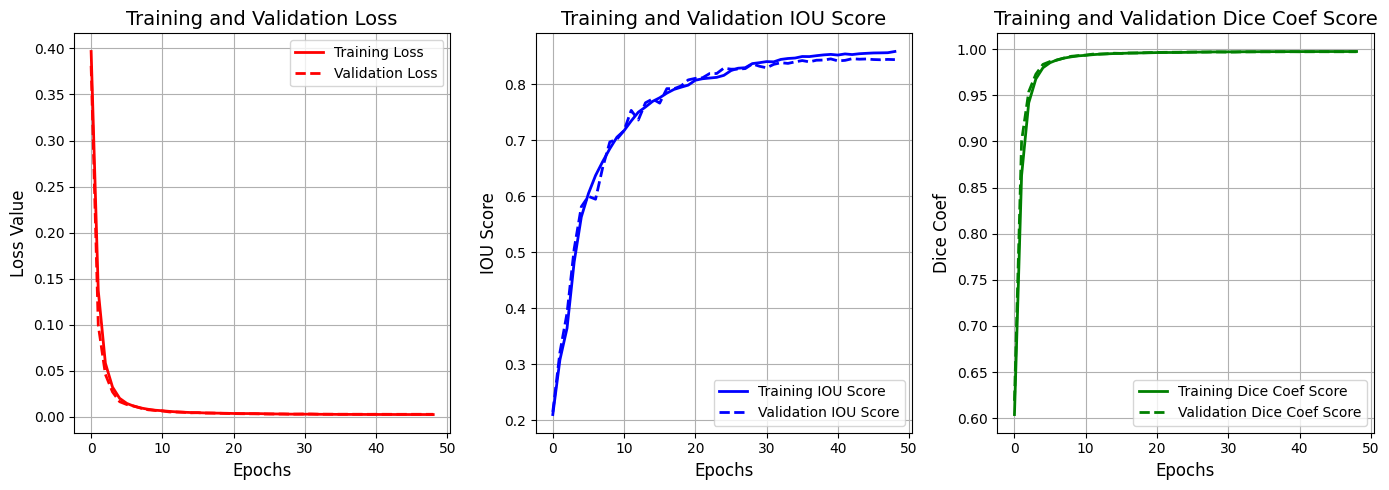

In [34]:
import matplotlib.pyplot as plt

loss = history_2.history['loss']
val_loss = history_2.history['val_loss']

iou = history_2.history['iou_score']
val_iou = history_2.history['val_iou_score']

dice_hist = history_2.history['dice_coef']
val_dice_hist = history_2.history['val_dice_coef']


epochs_range = range(len(loss))


plt.figure(figsize=(14, 5))


plt.subplot(1, 3, 1)
plt.plot(epochs_range, loss, label='Training Loss', color='red', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='red', linewidth=2, linestyle='--')
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss Value', fontsize=12)
plt.legend()
plt.grid(True)


plt.subplot(1, 3, 2)
plt.plot(epochs_range, iou, label='Training IOU Score', color='blue', linewidth=2)
plt.plot(epochs_range, val_iou, label='Validation IOU Score', color='blue', linewidth=2, linestyle='--')
plt.title('Training and Validation IOU Score', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('IOU Score', fontsize=12)
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(epochs_range, dice_hist, label='Training Dice Coef Score', color='green', linewidth=2)
plt.plot(epochs_range, val_dice_hist, label='Validation Dice Coef Score', color='green', linewidth=2, linestyle='--')
plt.title('Training and Validation Dice Coef Score', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Dice Coef', fontsize=12)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


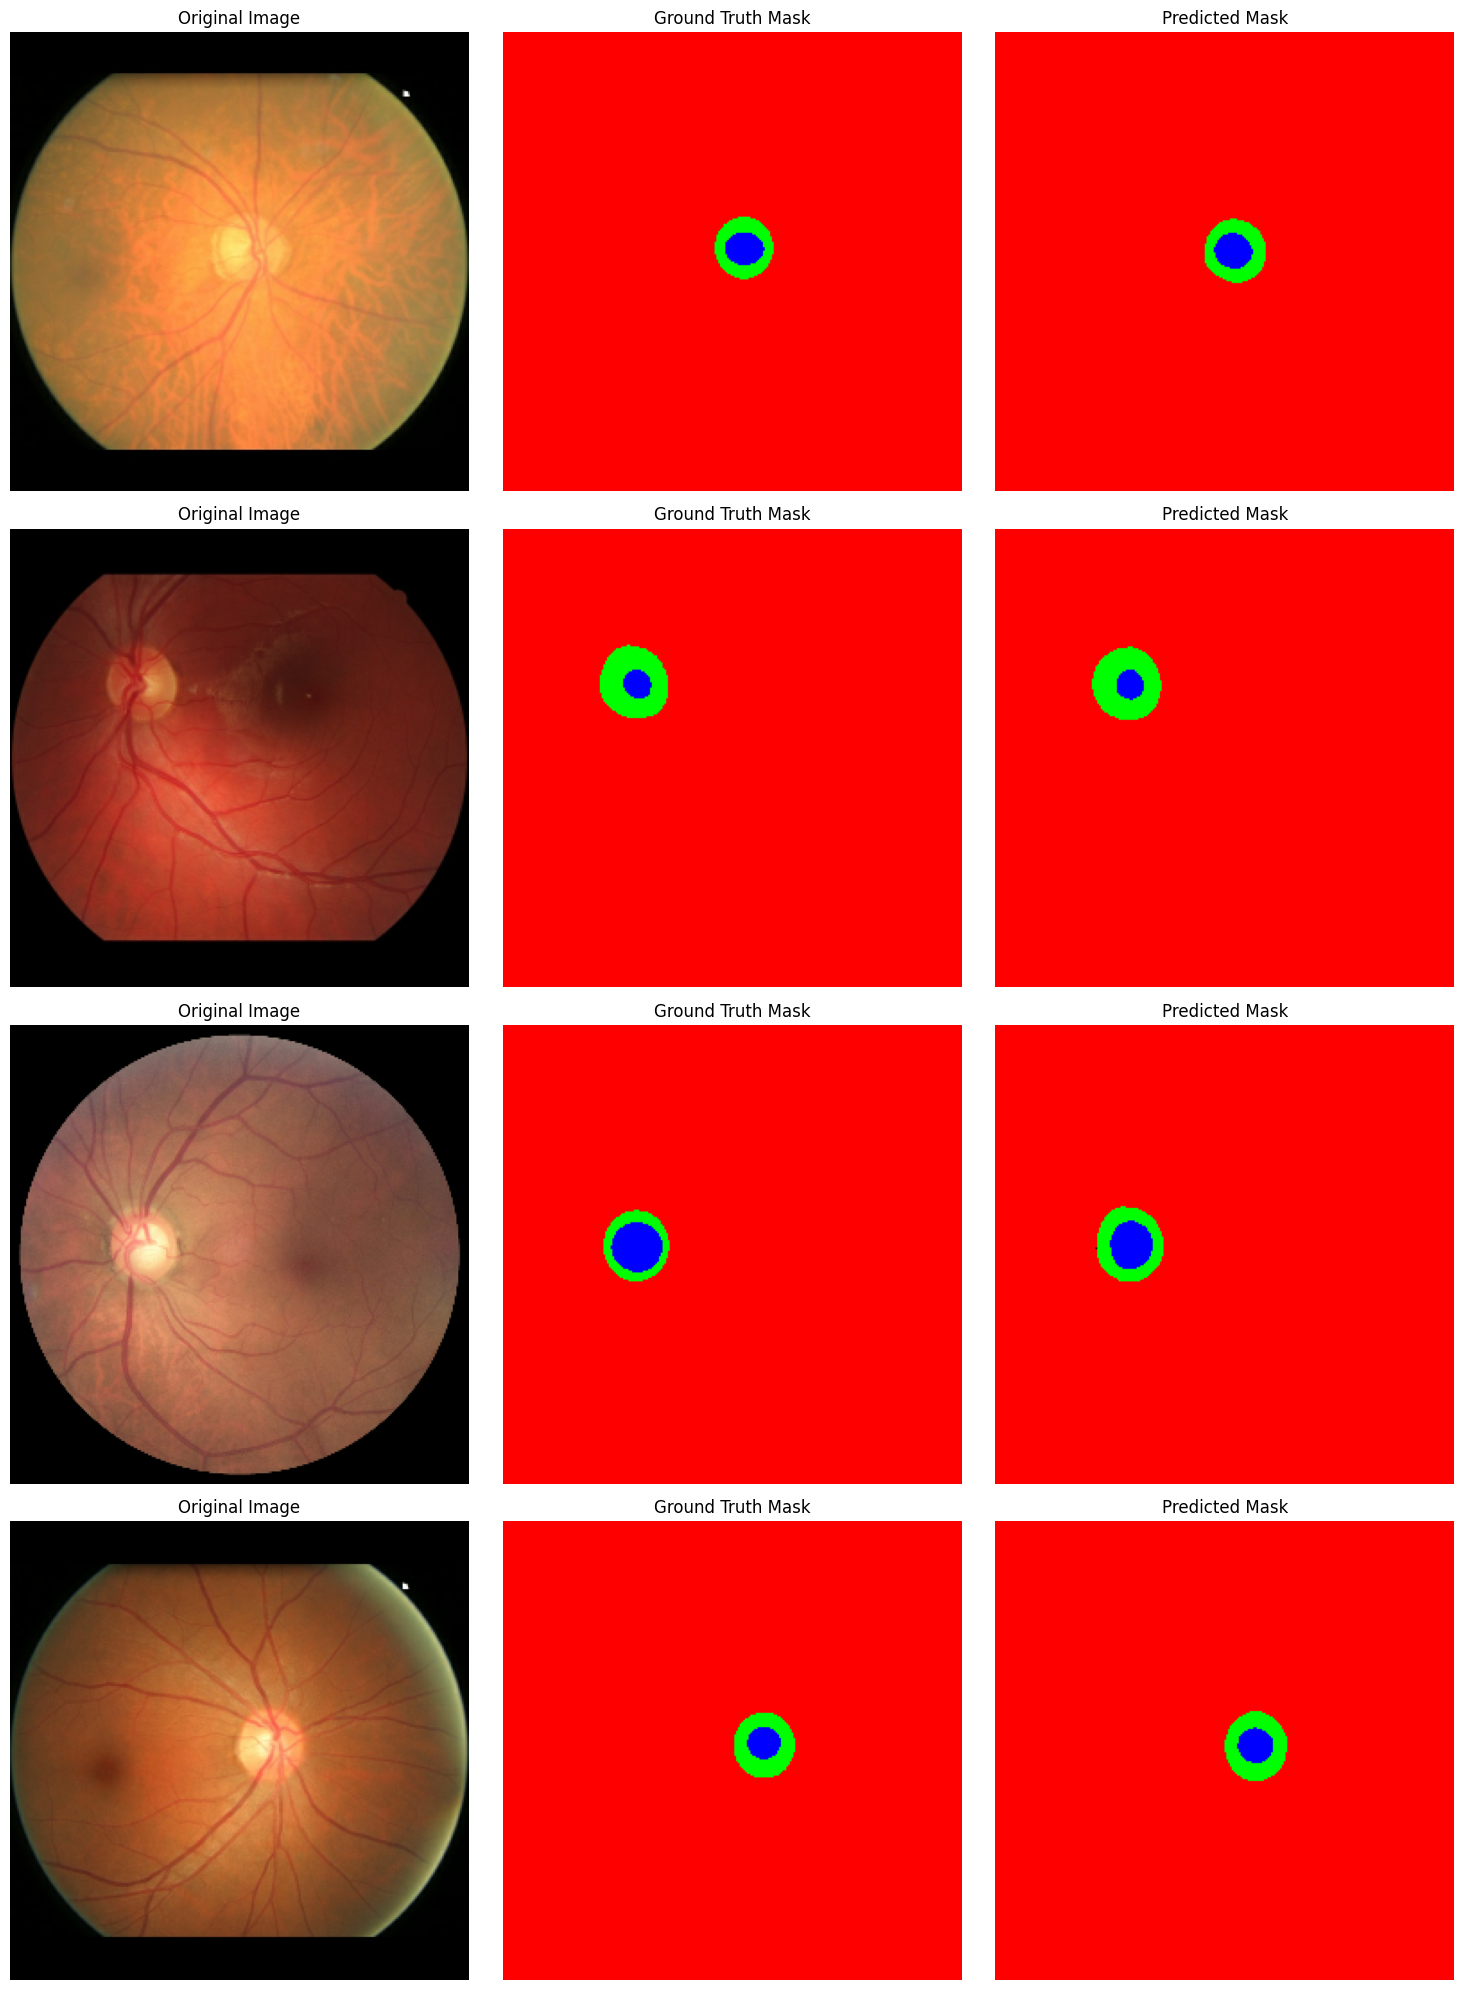

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf


best_model = tf.keras.models.load_model(
    "/kaggle/working/best_glaucoma_model_VGG16.keras", 
    compile=False
)


def visualize_predictions(dataset, model, num_samples=3):
    plt.figure(figsize=(15, 5 * num_samples))
    
    for images, masks in dataset.take(1):
        preds = model.predict(images)
        
        for i in range(min(num_samples, len(images))):
            img = images[i].numpy()
            true_mask = masks[i].numpy().squeeze()
            pred_mask = preds[i].squeeze()
            
            
            pred_mask = np.where(pred_mask > 0.5, 1.0, 0.0)
            
           
            plt.subplot(num_samples, 3, i * 3 + 1)
            plt.imshow(img)
            plt.title("Original Image", fontsize=12)
            plt.axis("off")
            
            
            plt.subplot(num_samples, 3, i * 3 + 2)
            plt.imshow(true_mask, cmap='gray')
            plt.title("Ground Truth Mask", fontsize=12)
            plt.axis("off")
            
            
            plt.subplot(num_samples, 3, i * 3 + 3)
            plt.imshow(pred_mask, cmap='gray')
            plt.title("Predicted Mask", fontsize=12)
            plt.axis("off")
            
    plt.tight_layout()
    plt.show()


visualize_predictions(val_dataset, best_model, num_samples=4)

In [36]:
import os
os.environ["SM_FRAMEWORK"] = "tf.keras"

import segmentation_models as sm
from segmentation_models import Unet
from segmentation_models.losses import bce_jaccard_loss
from segmentation_models.metrics import iou_score

BACKBONE = 'mobilenetv2'  
LR = 0.0001

model = Unet(
    backbone_name=BACKBONE, 
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    classes=3, 
    activation='softmax',
    encoder_weights='imagenet'
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss= dice_loss,
    metrics=[iou_score, dice_coef]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_pad           │ (None, 257, 257,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 128, 128,  │        864 │ Conv1_pad[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 128, 128,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 128, 128,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 128, 128,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 128, 128,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 128, 128,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 129, 129,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 64, 64,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │          0 │ block_1_depthwis

 Total params: 8,047,731 (30.70 MB)

 Trainable params: 8,011,635 (30.56 MB)

 Non-trainable params: 36,096 (141.00 KB)

In [37]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_glaucoma_model_mobilenetv2.keras",
        monitor="val_iou_score",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_iou_score",
        patience=6,
        restore_best_weights=True,
        verbose=1,
        mode='max'
    )
]

EPOCHS = 100

history_3 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/100


2026-10-28 17:20:40.639369: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:20:40.776728: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:20:45.968100: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:20:46.322019: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


133/134 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - dice_coef: 0.4998 - iou_score: 0.1730 - loss: 0.5002

2026-10-28 17:22:02.019562: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:22:02.157088: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:22:05.680153: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:22:05.999670: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:22:06.558554: E external/local_xla/xla/stream_

134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 582ms/step - dice_coef: 0.5007 - iou_score: 0.1734 - loss: 0.4993

2026-10-28 17:22:55.824103: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:22:55.964916: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:22:56.101819: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:22:56.246390: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:22:56.383317: E external/local_xla/xla/stream_


Epoch 1: val_iou_score improved from None to 0.24176, saving model to best_glaucoma_model_mobilenetv2.keras

Epoch 1: finished saving model to best_glaucoma_model_mobilenetv2.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 183s 781ms/step - dice_coef: 0.6216 - iou_score: 0.2167 - loss: 0.3791 - val_dice_coef: 0.6980 - val_iou_score: 0.2418 - val_loss: 0.3020 - learning_rate: 1.0000e-04
Epoch 2/100
134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - dice_coef: 0.8577 - iou_score: 0.3095 - loss: 0.1423
Epoch 2: val_iou_score improved from 0.24176 to 0.31518, saving model to best_glaucoma_model_mobilenetv2.keras

Epoch 2: finished saving model to best_glaucoma_model_mobilenetv2.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 36s 258ms/step - dice_coef: 0.8866 - iou_score: 0.3258 - loss: 0.1136 - val_dice_coef: 0.8814 - val_iou_score: 0.3152 - val_loss: 0.1186 - learning_rate: 1.0000e-04
Epoch 3/100
134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - dice_coef: 0.9387 - iou_score: 0.3670 - loss: 0.0613
Epoch 3: val_iou_score im

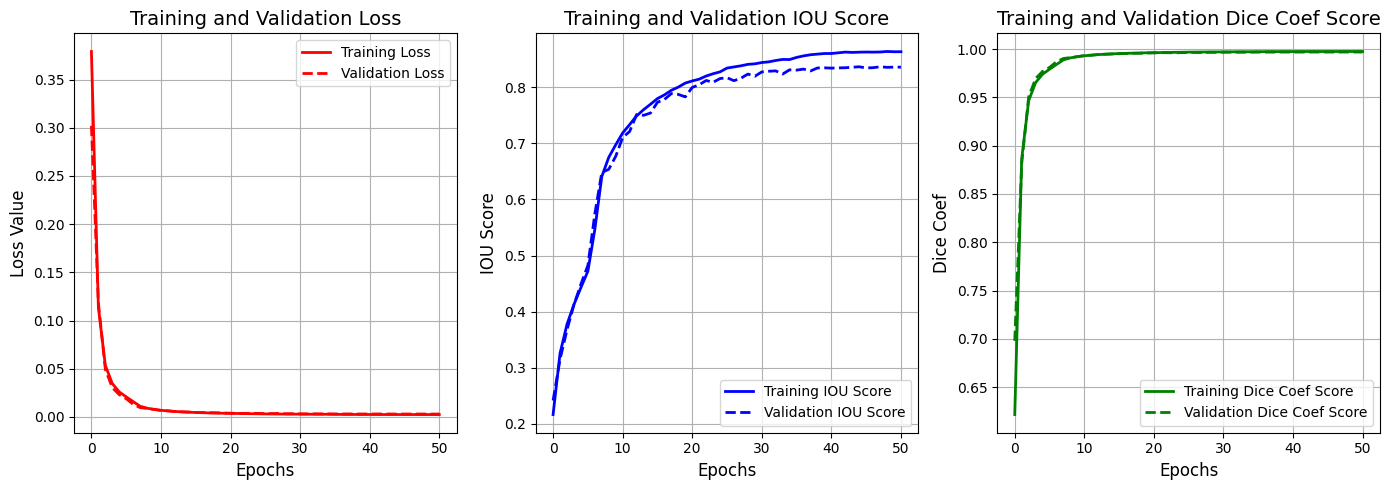

In [38]:
import matplotlib.pyplot as plt

loss = history_3.history['loss']
val_loss = history_3.history['val_loss']

iou = history_3.history['iou_score']
val_iou = history_3.history['val_iou_score']

dice_hist = history_3.history['dice_coef']
val_dice_hist = history_3.history['val_dice_coef']


epochs_range = range(len(loss))


plt.figure(figsize=(14, 5))


plt.subplot(1, 3, 1)
plt.plot(epochs_range, loss, label='Training Loss', color='red', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='red', linewidth=2, linestyle='--')
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss Value', fontsize=12)
plt.legend()
plt.grid(True)


plt.subplot(1, 3, 2)
plt.plot(epochs_range, iou, label='Training IOU Score', color='blue', linewidth=2)
plt.plot(epochs_range, val_iou, label='Validation IOU Score', color='blue', linewidth=2, linestyle='--')
plt.title('Training and Validation IOU Score', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('IOU Score', fontsize=12)
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(epochs_range, dice_hist, label='Training Dice Coef Score', color='green', linewidth=2)
plt.plot(epochs_range, val_dice_hist, label='Validation Dice Coef Score', color='green', linewidth=2, linestyle='--')
plt.title('Training and Validation Dice Coef Score', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Dice Coef', fontsize=12)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


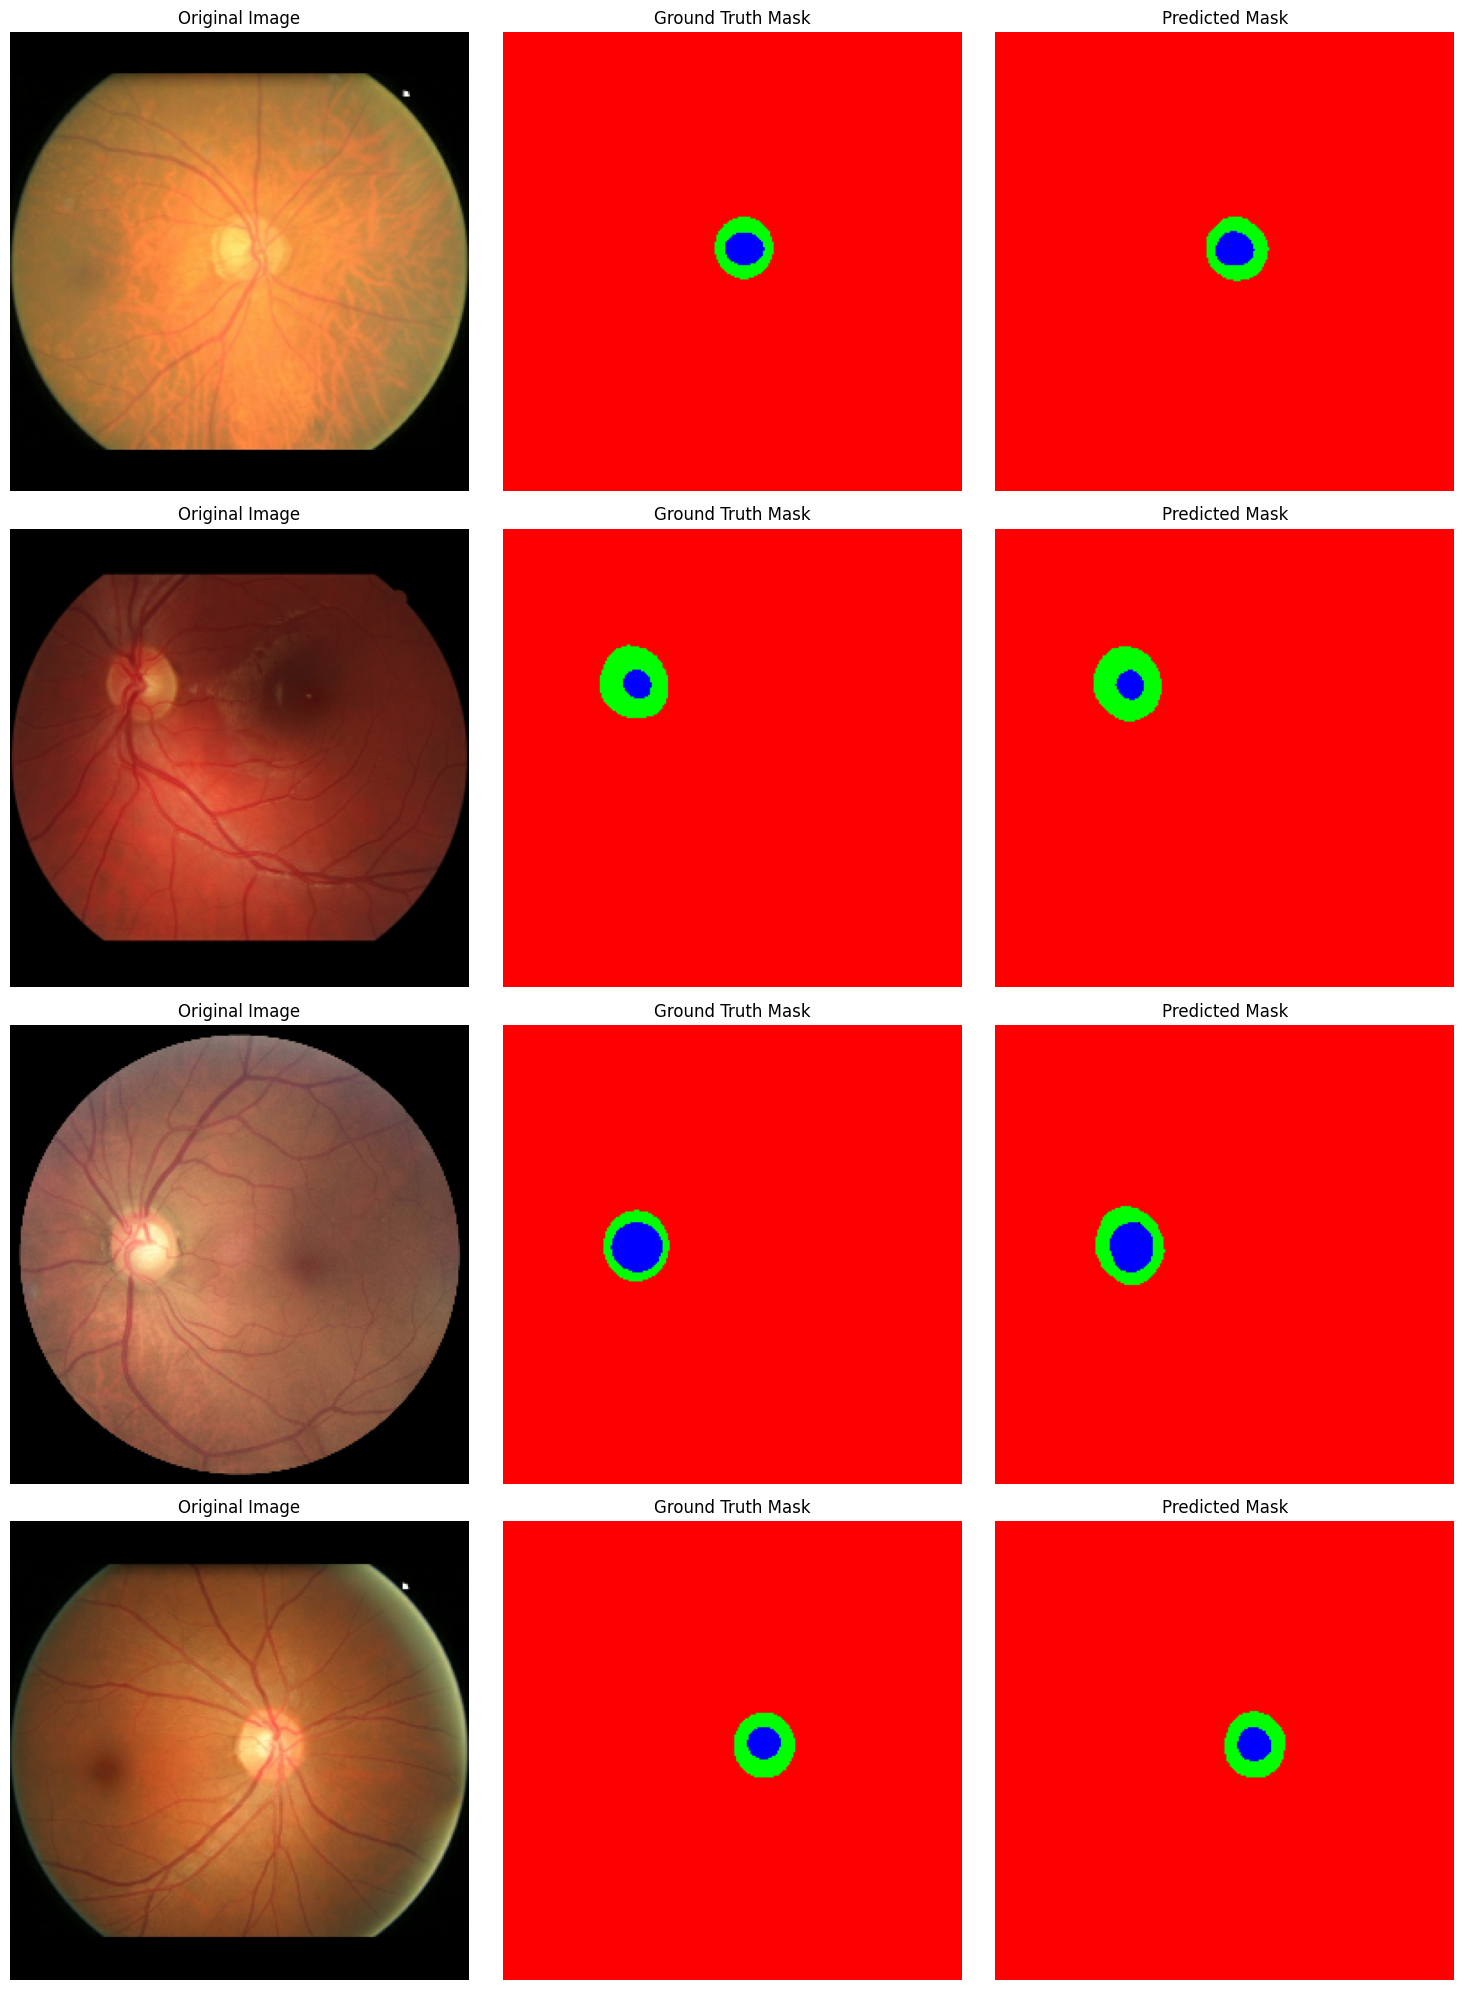

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf


best_model = tf.keras.models.load_model(
    "/kaggle/working/best_glaucoma_model_mobilenetv2.keras", 
    compile=False
)


def visualize_predictions(dataset, model, num_samples=3):
    plt.figure(figsize=(15, 5 * num_samples))
    
    for images, masks in dataset.take(1):
        preds = model.predict(images)
        
        for i in range(min(num_samples, len(images))):
            img = images[i].numpy()
            true_mask = masks[i].numpy().squeeze()
            pred_mask = preds[i].squeeze()
            
            
            pred_mask = np.where(pred_mask > 0.5, 1.0, 0.0)
            
           
            plt.subplot(num_samples, 3, i * 3 + 1)
            plt.imshow(img)
            plt.title("Original Image", fontsize=12)
            plt.axis("off")
            
            
            plt.subplot(num_samples, 3, i * 3 + 2)
            plt.imshow(true_mask, cmap='gray')
            plt.title("Ground Truth Mask", fontsize=12)
            plt.axis("off")
            
            
            plt.subplot(num_samples, 3, i * 3 + 3)
            plt.imshow(pred_mask, cmap='gray')
            plt.title("Predicted Mask", fontsize=12)
            plt.axis("off")
            
    plt.tight_layout()
    plt.show()


visualize_predictions(val_dataset, best_model, num_samples=4)

,Params (M),Epochs trained,Train IoU (last),Val Loss,Val IoU,Val Dice
Model,,,,,,
VGG16,23.8,49,0.8586,0.0029,0.8457,0.9971
MobileNetV2,8.0,51,0.8630,0.0031,0.8362,0.9969
ResNet34,24.5,49,0.5561,0.0060,0.5518,0.9940


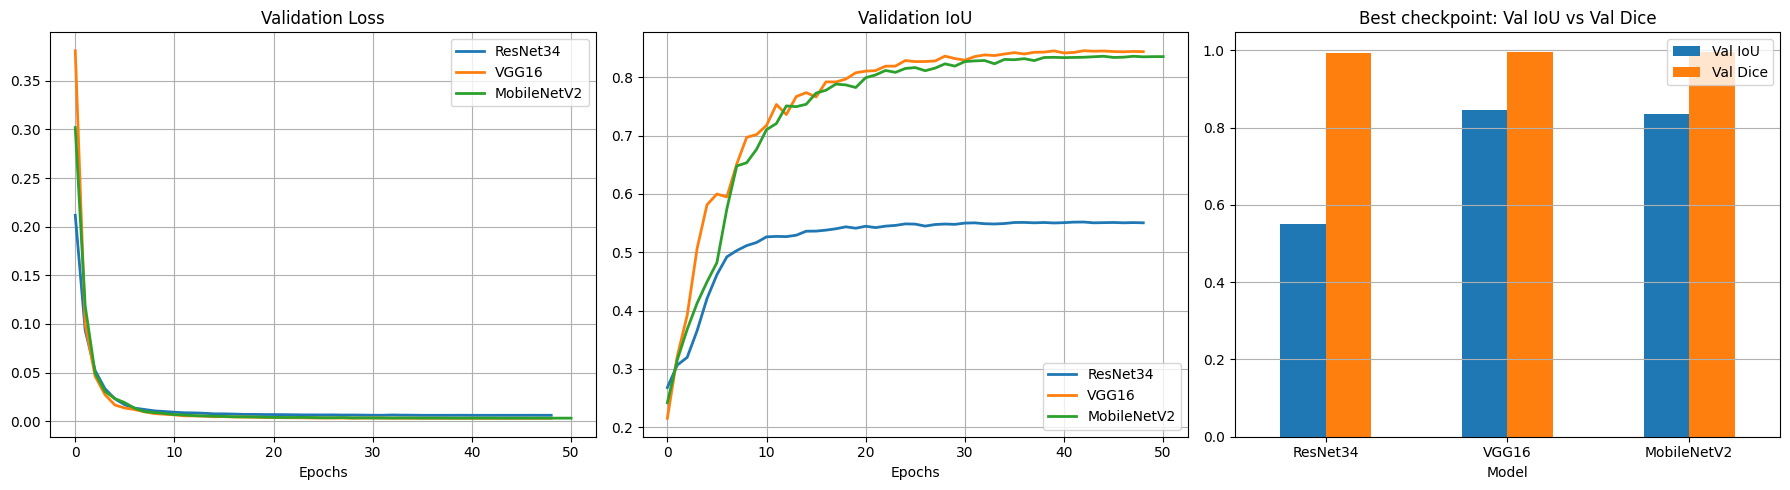

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from segmentation_models.metrics import iou_score

models_info = {
    "ResNet34":    ("best_glaucoma_model_ResNet34.keras",    history_1),
    "VGG16":       ("best_glaucoma_model_VGG16.keras",       history_2),
    "MobileNetV2": ("best_glaucoma_model_mobilenetv2.keras", history_3),
}

rows = []
for name, (path, hist) in models_info.items():
    m = tf.keras.models.load_model(f"/kaggle/working/{path}", compile=False)
    m.compile(loss=dice_loss, metrics=[iou_score, dice_coef])
    val_loss, val_iou, val_dice = m.evaluate(val_dataset, verbose=0)
    rows.append({
        "Model": name,
        "Params (M)": round(m.count_params() / 1e6, 1),
        "Epochs trained": len(hist.history["loss"]),
        "Train IoU (last)": round(hist.history["iou_score"][-1], 4),
        "Val Loss": round(val_loss, 4),
        "Val IoU": round(val_iou, 4),
        "Val Dice": round(val_dice, 4),
    })

results_df = pd.DataFrame(rows).set_index("Model")
display(results_df.sort_values("Val Dice", ascending=False))

colors = {"ResNet34": "tab:blue", "VGG16": "tab:orange", "MobileNetV2": "tab:green"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for name, (_, hist) in models_info.items():
    axes[0].plot(hist.history["val_loss"], label=name, color=colors[name], linewidth=2)
    axes[1].plot(hist.history["val_iou_score"], label=name, color=colors[name], linewidth=2)

axes[0].set_title("Validation Loss"); axes[0].set_xlabel("Epochs"); axes[0].legend(); axes[0].grid(True)
axes[1].set_title("Validation IoU");  axes[1].set_xlabel("Epochs"); axes[1].legend(); axes[1].grid(True)

results_df[["Val IoU", "Val Dice"]].plot(kind="bar", ax=axes[2], rot=0)
axes[2].set_title("Best checkpoint: Val IoU vs Val Dice"); axes[2].grid(True, axis="y")

plt.tight_layout()
plt.show()

In [41]:
# Final evaluation on the held-out TEST set (REFUGE) - never seen in training/validation
import pandas as pd
from segmentation_models.metrics import iou_score

test_models = {
    "ResNet34":    "best_glaucoma_model_ResNet34.keras",
    "VGG16":       "best_glaucoma_model_VGG16.keras",
    "MobileNetV2": "best_glaucoma_model_mobilenetv2.keras",
}

rows = []
for name, path in test_models.items():
    m = tf.keras.models.load_model(f"/kaggle/working/{path}", compile=False)
    m.compile(loss=dice_loss, metrics=[iou_score, dice_coef])
    t_loss, t_iou, t_dice = m.evaluate(test_dataset, verbose=0)
    rows.append({
        "Model": name,
        "Test Loss": round(t_loss, 4),
        "Test IoU": round(t_iou, 4),
        "Test Dice": round(t_dice, 4),
    })

test_results_df = pd.DataFrame(rows).set_index("Model")
display(test_results_df.sort_values("Test Dice", ascending=False))

,Test Loss,Test IoU,Test Dice
Model,,,
VGG16,0.0026,0.8703,0.9974
MobileNetV2,0.0028,0.8598,0.9972
ResNet34,0.0062,0.5508,0.9938


Loading model from: /kaggle/working/best_glaucoma_model_VGG16.keras ...
Model loaded successfully!



2026-10-28 17:53:01.960291: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:53:02.166964: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:53:02.684636: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 17:53:02.952539: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


--- Sample 1 (T0204.jpg) ---
  [Disc] Dice: 0.9622 | IoU: 0.9272
  [Cup]  Dice: 0.9175 | IoU: 0.8475
  [vCDR] True: 0.5641 | Pred: 0.5250 | Error: 0.0391

--- Sample 2 (T0267.jpg) ---
  [Disc] Dice: 0.9667 | IoU: 0.9355
  [Cup]  Dice: 0.9390 | IoU: 0.8850
  [vCDR] True: 0.6389 | Pred: 0.6053 | Error: 0.0336

--- Sample 3 (T0191.jpg) ---
  [Disc] Dice: 0.9382 | IoU: 0.8837
  [Cup]  Dice: 0.8714 | IoU: 0.7720
  [vCDR] True: 0.5500 | Pred: 0.5263 | Error: 0.0237



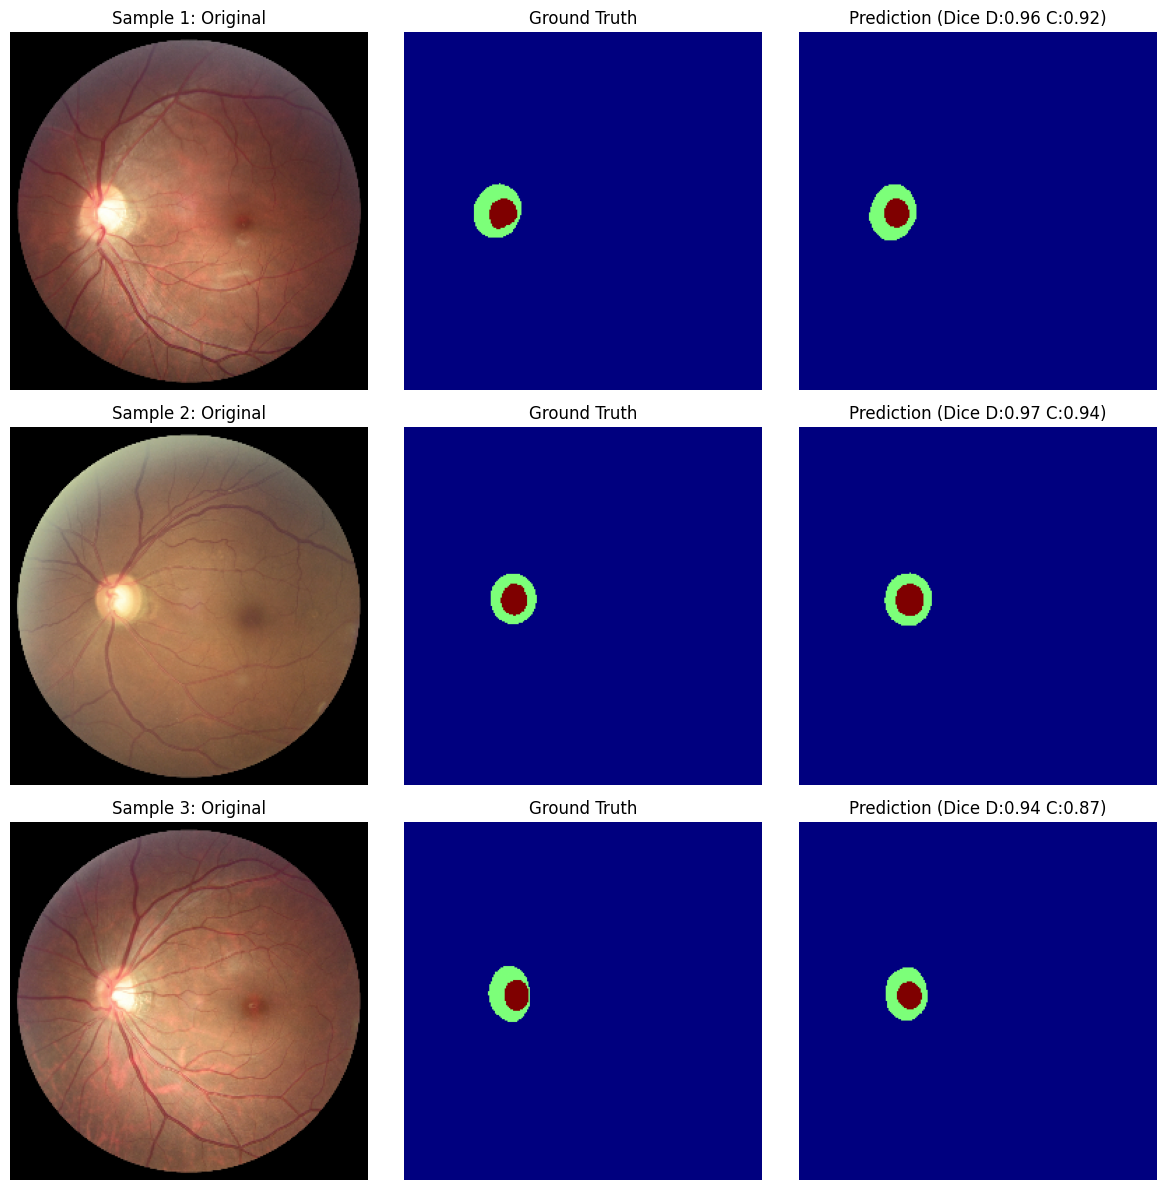

In [42]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

def evaluate_and_visualize_model(model_path, image_paths, mask_paths, num_samples=3, img_height=256, img_width=256):
    """
    Loads a saved multi-class segmentation model, runs inference, prints evaluation 
    metrics (Dice, IoU, vCDR), and plots side-by-side comparisons.
    """
    # 1. Load the saved model
    print(f"Loading model from: {model_path} ...")
    model = tf.keras.models.load_model(model_path, compile=False)
    print("Model loaded successfully!\n")
    
    # Select random samples
    total_samples = len(image_paths)
    sample_count = min(num_samples, total_samples)
    indices = np.random.choice(total_samples, size=sample_count, replace=False)
    
    # Set up the visualization plot
    plt.figure(figsize=(12, 4 * sample_count))
    
    for i, idx in enumerate(indices):
        img_path = image_paths[idx]
        mask_path = mask_paths[idx]
        
        # --- Preprocess Image ---
        img_file = tf.io.read_file(img_path)
        image = tf.image.decode_image(img_file, channels=3, expand_animations=False)
        image = tf.image.resize(image, [img_height, img_width])
        processed_img = tf.cast(image, tf.float32) / 255.0
        
        # --- Preprocess Ground Truth Mask ---
        mask_file = tf.io.read_file(mask_path)
        true_mask_raw = tf.image.decode_image(mask_file, channels=1, expand_animations=False)
        true_mask_raw = tf.image.resize(true_mask_raw, [img_height, img_width], method='nearest')
        true_mask = tf.cast(tf.round(true_mask_raw), tf.int32).numpy().squeeze()
        
        # --- Model Prediction ---
        pred_input = tf.expand_dims(processed_img, axis=0)
        pred_probs = model.predict(pred_input, verbose=0)
        pred_mask = tf.argmax(pred_probs, axis=-1).numpy()[0] # Shape: [H, W] with values 0, 1, 2
        
        # --- Metrics Calculation ---
        # 1. Extract Disc (1 and 2) and Cup (2 only)
        true_disc = np.isin(true_mask, [1, 2]).astype(np.uint8)
        true_cup  = (true_mask == 2).astype(np.uint8)
        
        pred_disc = np.isin(pred_mask, [1, 2]).astype(np.uint8)
        pred_cup  = (pred_mask == 2).astype(np.uint8)
        
        def compute_dice_iou(t, p):
            intersection = np.sum(t * p)
            union_sum = np.sum(t) + np.sum(p)
            if union_sum == 0:
                return 1.0, 1.0
            dice = (2.0 * intersection) / union_sum
            iou = intersection / (np.sum(t) + np.sum(p) - intersection)
            return dice, iou
            
        disc_dice, disc_iou = compute_dice_iou(true_disc, pred_disc)
        cup_dice, cup_iou   = compute_dice_iou(true_cup, pred_cup)
        
        # 2. Calculate vCDR (Vertical Cup-to-Disc Ratio)
        def get_vcdr(cup, disc):
            def get_height(mask):
                rows = np.any(mask, axis=1)
                if not np.any(rows):
                    return 0
                idx = np.where(rows)[0]
                return idx[-1] - idx[0] + 1
            cup_h = get_height(cup)
            disc_h = get_height(disc)
            return cup_h / (disc_h + 1e-7)
            
        true_vcdr = get_vcdr(true_cup, true_disc)
        pred_vcdr = get_vcdr(pred_cup, pred_disc)
        vcdr_error = abs(true_vcdr - pred_vcdr)
        
        # Print metrics for this sample in the console
        print(f"--- Sample {i+1} ({os.path.basename(img_path)}) ---")
        print(f"  [Disc] Dice: {disc_dice:.4f} | IoU: {disc_iou:.4f}")
        print(f"  [Cup]  Dice: {cup_dice:.4f} | IoU: {cup_iou:.4f}")
        print(f"  [vCDR] True: {true_vcdr:.4f} | Pred: {pred_vcdr:.4f} | Error: {vcdr_error:.4f}\n")
        
        # --- Plotting Comparisons ---
        plt.subplot(sample_count, 3, i * 3 + 1)
        plt.imshow(processed_img.numpy())
        plt.title(f"Sample {i+1}: Original")
        plt.axis('off')
        
        plt.subplot(sample_count, 3, i * 3 + 2)
        plt.imshow(true_mask, cmap='jet', vmin=0, vmax=2)
        plt.title(f"Ground Truth")
        plt.axis('off')
        
        plt.subplot(sample_count, 3, i * 3 + 3)
        plt.imshow(pred_mask, cmap='jet', vmin=0, vmax=2)
        plt.title(f"Prediction (Dice D:{disc_dice:.2f} C:{cup_dice:.2f})")
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()
img_dir = "/kaggle/input/datasets/arnavjain1/glaucoma-datasets/REFUGE/test/Images"
mask_dir = "/kaggle/input/datasets/arnavjain1/glaucoma-datasets/REFUGE/test/Masks"

test_imgs = sorted(glob.glob(os.path.join(img_dir, "*.jpg")))
test_masks = sorted(glob.glob(os.path.join(mask_dir, "*.png")))

evaluate_and_visualize_model(
    model_path="/kaggle/working/best_glaucoma_model_VGG16.keras",
    image_paths=test_imgs,
    mask_paths=test_masks,
    num_samples=3
)

Loading model from: /kaggle/working/best_glaucoma_model_VGG16.keras ...


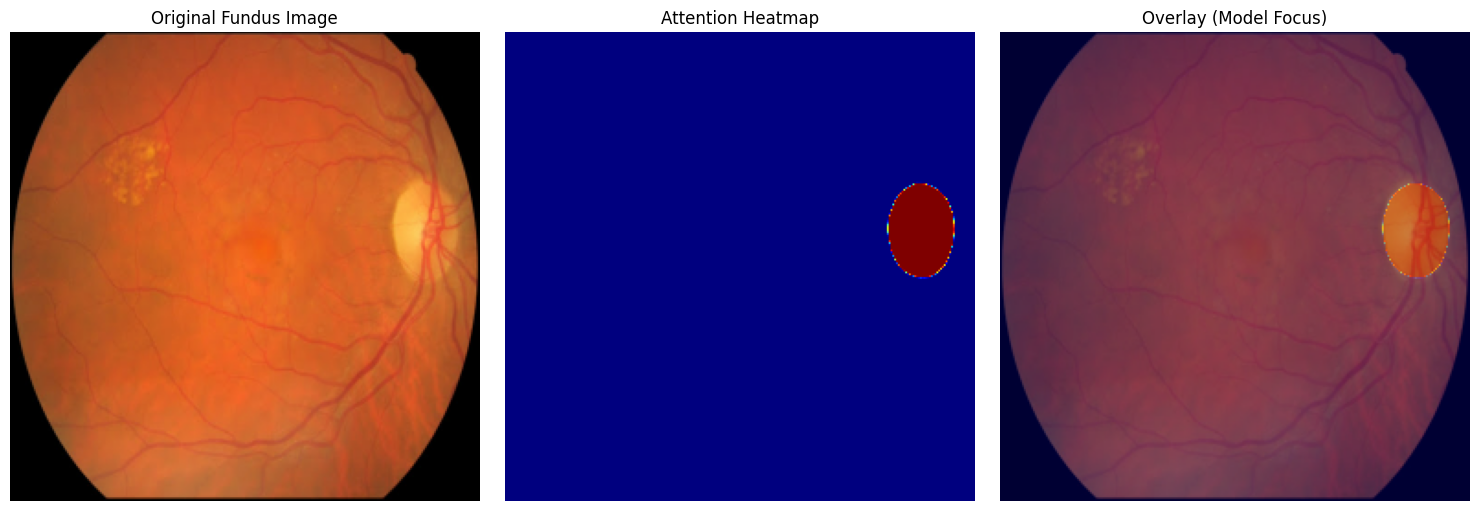

In [47]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import glob

def generate_segmentation_heatmap(model_path, image_path, img_height=256, img_width=256):
    print(f"Loading model from: {model_path} ...")
    model = tf.keras.models.load_model(model_path, compile=False)
    
    img_file = tf.io.read_file(image_path)
    image = tf.image.decode_image(img_file, channels=3, expand_animations=False)
    image = tf.image.resize(image, [img_height, img_width])
    processed_img = tf.cast(image, tf.float32) / 255.0
    
    input_tensor = tf.expand_dims(processed_img, axis=0)
    
    with tf.GradientTape() as tape:
        preds = model(input_tensor)
        target_class_output = preds[..., 2] 
        
    grads = tape.gradient(target_class_output, preds)
    
    pred_numpy = preds.numpy()[0]
    
    attention_map = pred_numpy[..., 1] + pred_numpy[..., 2]
    
    attention_map = np.maximum(attention_map, 0)
    if attention_map.max() != 0:
        attention_map = attention_map / attention_map.max()
        
    heatmap = cv2.resize(attention_map, (img_width, img_height))
    
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    

    original_img_np = (processed_img.numpy() * 255).astype(np.uint8)
    original_img_float = original_img_np.astype(np.float32)
    heatmap_float = heatmap_colored.astype(np.float32)
    
  
    superimposed_img = cv2.addWeighted(original_img_float, 0.6, heatmap_float, 0.4, 0)
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)
    
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    plt.imshow(original_img_np)
    plt.title("Original Fundus Image")
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap, cmap='jet')
    plt.title("Attention Heatmap")
    plt.axis('off')
    
    plt.subplot(1, 3, 3)
    plt.imshow(superimposed_img)
    plt.title("Overlay (Model Focus)")
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

img_dir = "/kaggle/input/datasets/basuoinymohamed/imgees"
test_imgs = sorted(glob.glob(os.path.join(img_dir, "*.jpg")))

if len(test_imgs) > 0:
    generate_segmentation_heatmap(
        model_path="/kaggle/working/best_glaucoma_model_VGG16.keras",
        image_path=test_imgs[1]
    )
else:
    print("No images found in the specified directory!")

Loading model from: /kaggle/working/best_glaucoma_model_VGG16.keras ...

--- Clinical Analysis ---
Patient vCDR: 0.3611 | Threshold: 0.5
Status: Normal (Safe)


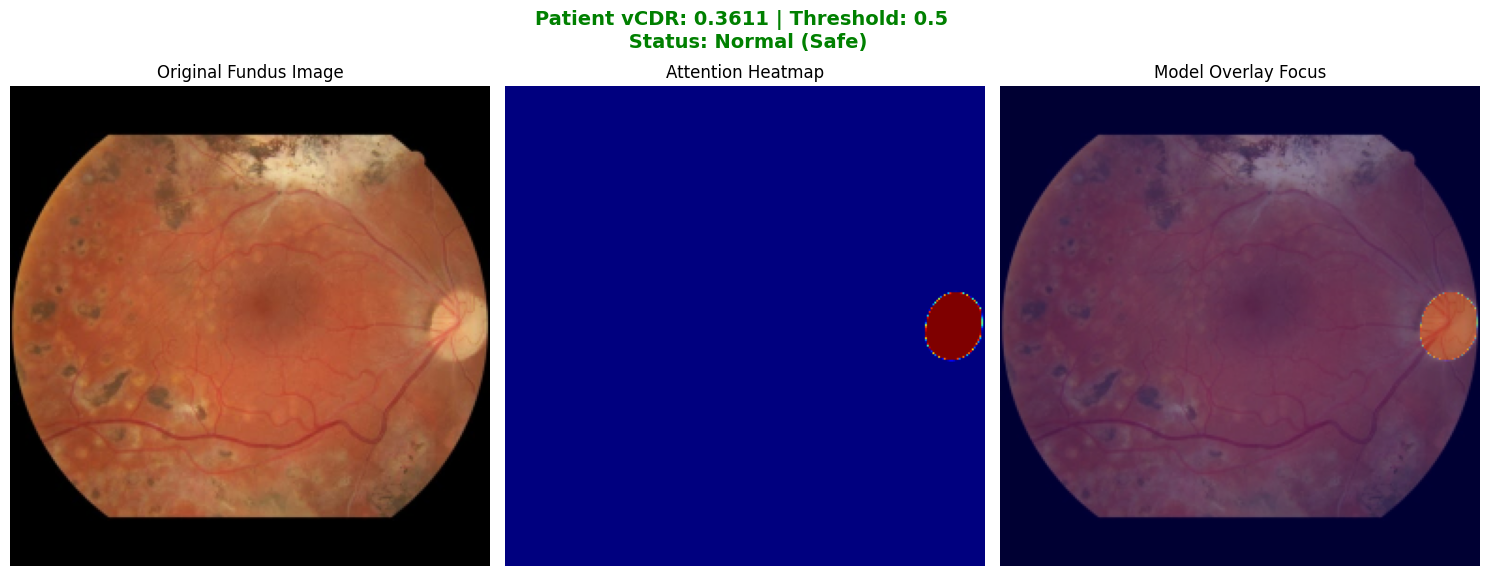

In [48]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import glob

def generate_segmentation_heatmap_with_vcdr(model_path, image_path, threshold=0.50, img_height=256, img_width=256):
    print(f"Loading model from: {model_path} ...")
    model = tf.keras.models.load_model(model_path, compile=False)
    
    img_file = tf.io.read_file(image_path)
    image = tf.image.decode_image(img_file, channels=3, expand_animations=False)
    image = tf.image.resize(image, [img_height, img_width])
    processed_img = tf.cast(image, tf.float32) / 255.0
    
    input_tensor = tf.expand_dims(processed_img, axis=0)
    
  
    preds = model(input_tensor) 
    pred_mask = np.argmax(preds.numpy()[0], axis=-1) 
    
    pred_disc = np.isin(pred_mask, [1, 2]).astype(np.uint8)
    pred_cup  = (pred_mask == 2).astype(np.uint8)
    
    def get_vertical_height(mask):
        rows = np.any(mask, axis=1)
        if not np.any(rows):
            return 0.0
        indices = np.where(rows)[0]
        return float(indices[-1] - indices[0] + 1)
    
    disc_height = get_vertical_height(pred_disc)
    cup_height  = get_vertical_height(pred_cup)
    
    patient_vcdr = round((cup_height / disc_height), 4) if disc_height > 0 else 0.0
    
 
    if patient_vcdr > threshold:
        status_text = f"High Risk (Glaucoma Detected)"
        status_color = "red"
    else:
        status_text = f"Normal (Safe)"
        status_color = "green"
        
    print(f"\n--- Clinical Analysis ---")
    print(f"Patient vCDR: {patient_vcdr} | Threshold: {threshold}")
    print(f"Status: {status_text}")
    

    pred_numpy = preds.numpy()[0]
    attention_map = pred_numpy[..., 1] + pred_numpy[..., 2]
    
    attention_map = np.maximum(attention_map, 0)
    if attention_map.max() != 0:
        attention_map = attention_map / attention_map.max()
        
    heatmap = cv2.resize(attention_map, (img_width, img_height))
    
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    
    original_img_np = (processed_img.numpy() * 255).astype(np.uint8)
    original_img_float = original_img_np.astype(np.float32)
    heatmap_float = heatmap_colored.astype(np.float32)
    
    superimposed_img = cv2.addWeighted(original_img_float, 0.6, heatmap_float, 0.4, 0)
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)
    
    
    plt.figure(figsize=(15, 6))
    
    plt.subplot(1, 3, 1)
    plt.imshow(original_img_np)
    plt.title("Original Fundus Image")
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap, cmap='jet')
    plt.title("Attention Heatmap")
    plt.axis('off')
    
    plt.subplot(1, 3, 3)
    plt.imshow(superimposed_img)
    plt.title("Model Overlay Focus")
    plt.axis('off')
    
     
    plt.suptitle(f"Patient vCDR: {patient_vcdr} | Threshold: {threshold} \n Status: {status_text}", 
                 fontsize=14, fontweight='bold', color=status_color)
    
    plt.tight_layout()
    plt.show()

img_dir = "/kaggle/input/datasets/basuoinymohamed/imgees"
test_imgs = sorted(glob.glob(os.path.join(img_dir, "*.jpg")))

if len(test_imgs) > 0:
    generate_segmentation_heatmap_with_vcdr(
        model_path="/kaggle/working/best_glaucoma_model_VGG16.keras",
        image_path=test_imgs[0],
        threshold=0.50
    )
else:
    print("No images found in the specified directory!")

Loading model from: /kaggle/working/best_glaucoma_model_VGG16.keras ...

--- Clinical Analysis ---
Patient vCDR: 0.4314 | Threshold: 0.5
Status: Normal (Safe)


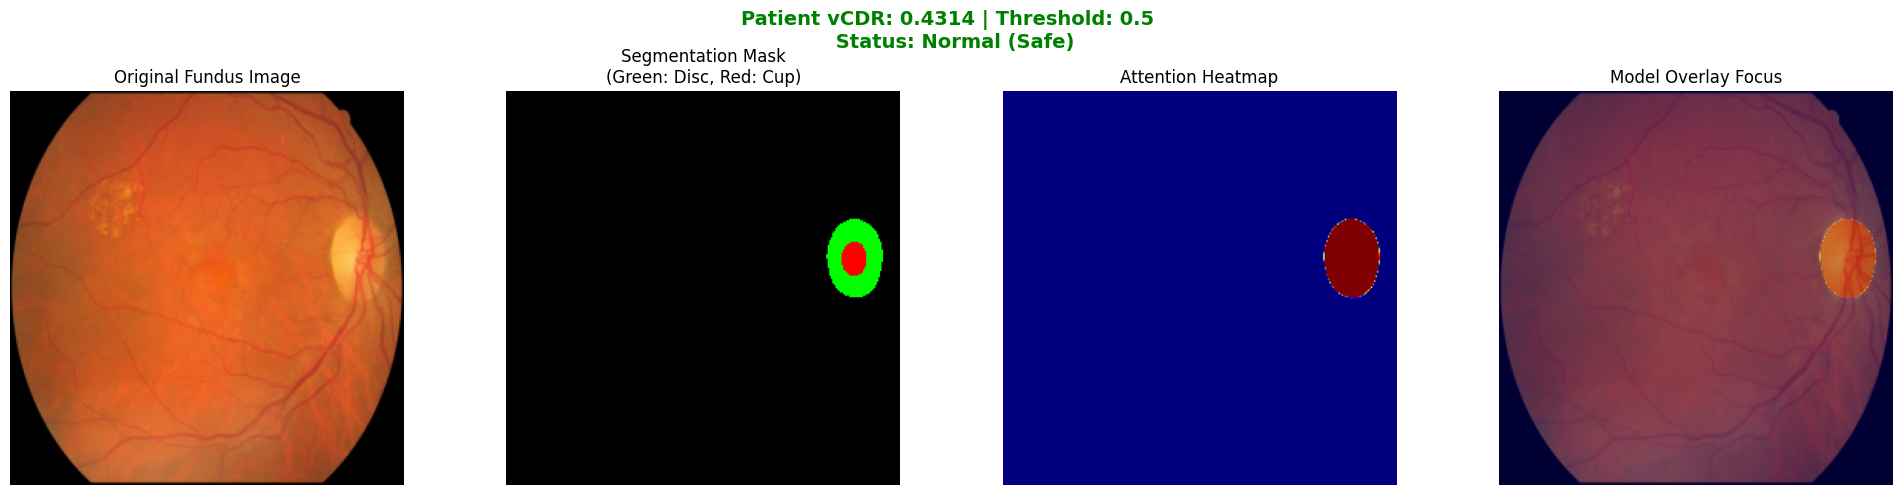

In [49]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import glob

def generate_full_clinical_visualization(model_path, image_path, threshold=0.50, img_height=256, img_width=256):
    print(f"Loading model from: {model_path} ...")
    model = tf.keras.models.load_model(model_path, compile=False)
    
    img_file = tf.io.read_file(image_path)
    image = tf.image.decode_image(img_file, channels=3, expand_animations=False)
    image = tf.image.resize(image, [img_height, img_width])
    processed_img = tf.cast(image, tf.float32) / 255.0
    
    input_tensor = tf.expand_dims(processed_img, axis=0)

    preds = model(input_tensor)
    pred_mask = np.argmax(preds.numpy()[0], axis=-1) 

    pred_disc = np.isin(pred_mask, [1, 2]).astype(np.uint8)
    pred_cup  = (pred_mask == 2).astype(np.uint8)
    
    def get_vertical_height(mask):
        rows = np.any(mask, axis=1)
        if not np.any(rows):
            return 0.0
        indices = np.where(rows)[0]
        return float(indices[-1] - indices[0] + 1)
    
    disc_height = get_vertical_height(pred_disc)
    cup_height  = get_vertical_height(pred_cup)
    
    patient_vcdr = round((cup_height / disc_height), 4) if disc_height > 0 else 0.0
    
   
    if patient_vcdr > threshold:
        status_text = f"High Risk (Glaucoma Detected)"
        status_color = "red"
    else:
        status_text = f"Normal (Safe)"
        status_color = "green"
        
    print(f"\n--- Clinical Analysis ---")
    print(f"Patient vCDR: {patient_vcdr} | Threshold: {threshold}")
    print(f"Status: {status_text}")
    
  
    mask_colored = np.zeros((img_height, img_width, 3), dtype=np.uint8)
    mask_colored[pred_disc == 1] = [0, 255, 0]   
    mask_colored[pred_cup == 1]  = [255, 0, 0]   

    pred_numpy = preds.numpy()[0]
    attention_map = pred_numpy[..., 1] + pred_numpy[..., 2]
    attention_map = np.maximum(attention_map, 0)
    if attention_map.max() != 0:
        attention_map = attention_map / attention_map.max()
        
    heatmap = cv2.resize(attention_map, (img_width, img_height))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    
    original_img_np = (processed_img.numpy() * 255).astype(np.uint8)
    original_img_float = original_img_np.astype(np.float32)
    heatmap_float = heatmap_colored.astype(np.float32)
    
    superimposed_img = cv2.addWeighted(original_img_float, 0.6, heatmap_float, 0.4, 0)
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)
    
   
    plt.figure(figsize=(20, 5))
    
    plt.subplot(1, 4, 1)
    plt.imshow(original_img_np)
    plt.title("Original Fundus Image")
    plt.axis('off')
    
    plt.subplot(1, 4, 2)
    plt.imshow(mask_colored)
    plt.title("Segmentation Mask\n(Green: Disc, Red: Cup)")
    plt.axis('off')
    
    plt.subplot(1, 4, 3)
    plt.imshow(heatmap, cmap='jet')
    plt.title("Attention Heatmap")
    plt.axis('off')
    
    plt.subplot(1, 4, 4)
    plt.imshow(superimposed_img)
    plt.title("Model Overlay Focus")
    plt.axis('off')
    
    plt.suptitle(f"Patient vCDR: {patient_vcdr} | Threshold: {threshold} \n Status: {status_text}", 
                 fontsize=14, fontweight='bold', color=status_color)
    
    plt.tight_layout()
    plt.show()

img_dir = "/kaggle/input/datasets/basuoinymohamed/imgees"
test_imgs = sorted(glob.glob(os.path.join(img_dir, "*.jpg")))

if len(test_imgs) > 0:
    generate_full_clinical_visualization(
        model_path="/kaggle/working/best_glaucoma_model_VGG16.keras",
        image_path=test_imgs[1],
        threshold=0.50
    )
else:
    print("No images found in the specified directory!")